In [1]:
# Probability Cal
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

In [2]:
df = pd.read_csv("Sachin_Tendulkar.csv")
df.head()

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25


In [3]:
runs = df["Runs"]
mean = runs.mean()
median = runs.median()
minim = runs.min()
maxim = runs.max()
std = runs.std()

Text(0.5, 1.0, 'Runs Frequency Distribution')

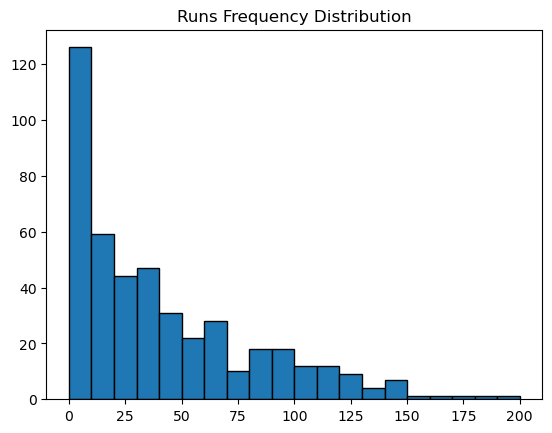

In [11]:
plt.hist(runs,bins = 20, edgecolor = "black")
plt.title("Runs Frequency Distribution")

Text(0.5, 1.0, 'Runs Boxplot')

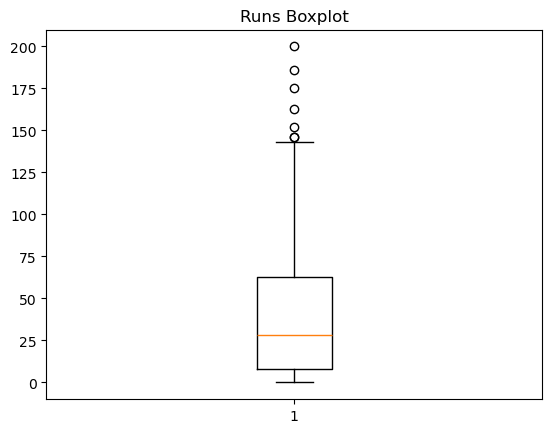

In [14]:
plt.boxplot(runs)
plt.title("Runs Boxplot")

In [ ]:
# 4 cal z-score for ball faced

In [21]:
#5
df["Runs_per_Ball"] = (runs/df["Balls_faced"])
df.head()

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Runs_per_Ball
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2,0.000000
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2,0.000000
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39,0.923077
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12,0.833333
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25,0.800000


In [23]:
#6
x = 50
y = 100


In [24]:
#Runs between x and y
between = df[(df["Runs"] >= x) & (df["Runs"] <= y )]
print(f"Between {x} and {y}")
print("Count=",len(between))
print("Percentage =", len(between) / len(df) * 100)

Between 50 and 100
Count= 102
Percentage = 22.566371681415927


In [25]:
# Normal Distr Prob
p_between = norm.cdf(y,mean,std) - norm.cdf(x,mean,std)
print("Normal probability = " , p_between)

Normal probability =  0.3392827468748292


In [26]:
#7 people with Runs up to x
up_to_x = df[df["Runs"] <= x]
print("Up to ", x)
print(f"Count = {len(up_to_x)}")
print(f"Percentage = {len(up_to_x) / len(df) * 100}")

Up to  50
Count = 309
Percentage = 68.36283185840708


In [28]:
up_to_x = norm.cdf(x,mean,std)
up_to_x

0.5912008884684711

In [31]:
#People with runs above x
x = 100
above_x = df[df["Runs"] > x]
print("Above",x)
print("Count=",len(above_x))
print("Percentage =",len(above_x)/len(df)*100)

Above 100
Count= 43
Percentage = 9.513274336283185


In [29]:
# 1 - CDF
p_above_x = 1 -norm.cdf(x,mean,std)
print("Normal Probability =", p_above_x)

Normal Probability = 0.4087991115315289


In [32]:
# 9
df.head()

,Match_No,Innings,match_date,Versus,mode_of_dismissal,Runs,Balls_faced,Runs_per_Ball
0,1,1,1989-12-18 00:00:00,Pakistan,c Wasim Akram b Waqar Younis,0,2,0.000000
1,2,2,1990-03-01 00:00:00,New Zealand,c & b S A Thomson,0,2,0.000000
2,3,3,1990-03-06 00:00:00,New Zealand,c †I D S Smith b S A Thomson,36,39,0.923077
3,4,4,1990-04-25 00:00:00,Sri Lanka,run out,10,12,0.833333
4,5,5,1990-04-27 00:00:00,Pakistan,c Saeed Anwar b Imran Khan,20,25,0.800000


In [41]:
df1 = df.groupby("Versus").agg(
    Average_Runs = ("Runs","mean")).reset_index()

In [42]:
df1.head()

,Versus,Average_Runs
0,Australia,43.957143
1,Bangladesh,45.090909
2,Bermuda,57.000000
3,England,39.324324
4,Ireland,21.000000


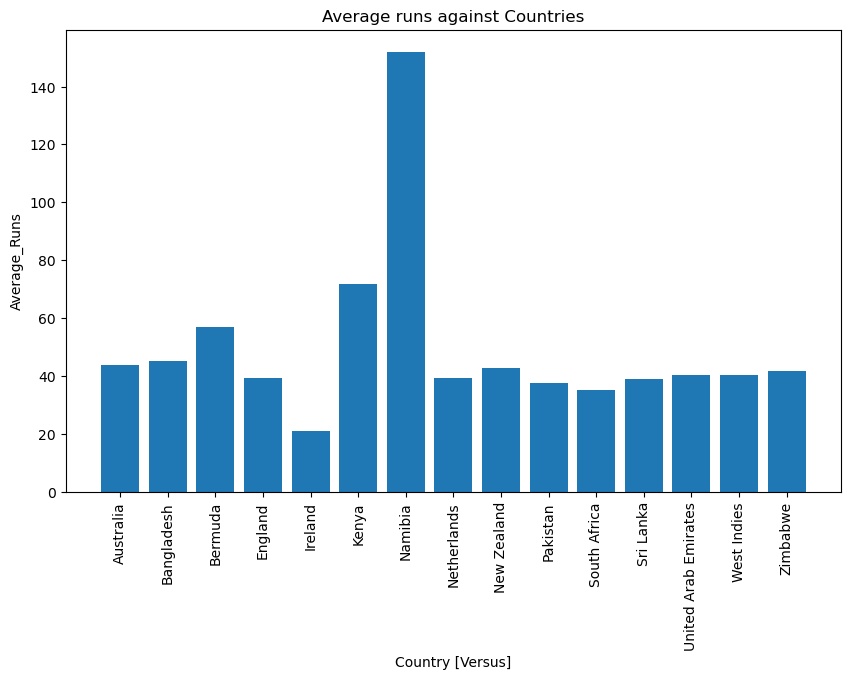

In [49]:
plt.figure(figsize=(10,6))
plt.bar(df1["Versus"],df1["Average_Runs"])
plt.xticks(rotation=90)
plt.xlabel("Country [Versus]")
plt.ylabel("Average_Runs")
plt.title("Average runs against Countries")
plt.show()